# 03 · Public data: daily wind speeds at 12 Irish stations

Daily average wind speeds (knots) at 12 meteorological stations in Ireland, 1961–1978 — the classic
space–time data set of Haslett and Raftery (1989, *JRSS C* 38, 1–50), distributed with the R package
**gstat** and downloaded here at run time. Following Haslett and Raftery we model square-root wind speeds.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # or: pip install -e .  (from the repository root)
import numpy as np
import matplotlib.pyplot as plt
import gstarx_pw as g
from gstarx_pw.plotting import set_style, plot_links, plot_bootstrap, plot_heatmaps, OKABE_ITO as C
set_style()
import pandas as pd

In [2]:
w = g.load_irish_wind()
S = w['speeds'].loc['1976-01-01':'1978-12-31']
Y = np.sqrt(S.to_numpy())
print(S.shape, 'days x stations'); pd.DataFrame({'station': w['stations'], 'lat': w['lat'].round(2), 'lon': w['lon'].round(2)}, index=w['codes']).T

(1096, 12) days x stations


,RPT,VAL,ROS,KIL,SHA,BIR,DUB,CLA,MUL,CLO,BEL,MAL
station,Roche's Point,Valentia,Roslare,Kilkenny,Shannon,Birr,Dublin,Claremorris,Mullingar,Clones,Belmullet,Malin Head
lat,51.8,51.93,52.28,52.67,52.7,53.08,53.43,53.72,53.53,54.18,54.23,55.37
lon,-8.25,-10.25,-6.36,-7.27,-8.92,-7.88,-6.25,-8.98,-7.37,-7.23,-10.0,-7.33


## 1. Exogenous stage: the annual cycle

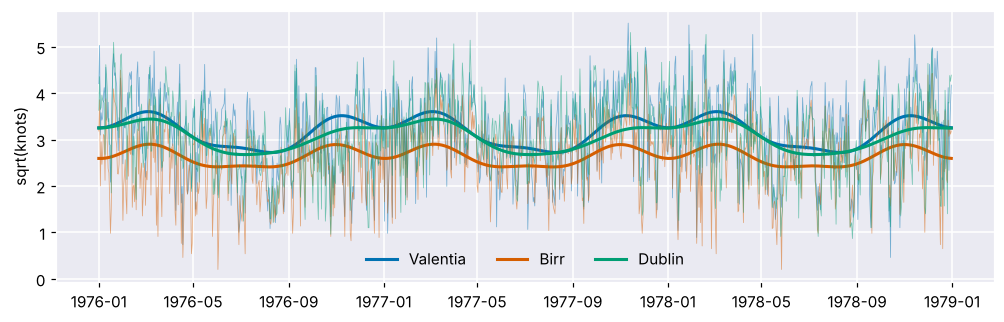

In [3]:
X = g.harmonic_design(len(Y), period=365.25, K=3)
B, Zhat = g.exogenous_stage(Y, X)
M = g.annihilator(X)
fig, ax = plt.subplots(figsize=(11, 3.2))
for k, c in enumerate(['VAL', 'BIR', 'DUB']):
    j = w['codes'].index(c)
    ax.plot(S.index, Y[:, j], lw=0.5, alpha=0.5, color=C[k]); ax.plot(S.index, X @ B[:, j], lw=2, color=C[k], label=w['stations'][j])
ax.legend(ncol=3); ax.set_ylabel('sqrt(knots)'); plt.show()

## 2. Are standard weight matrices adequate?

In [4]:
rng = np.random.default_rng(7)
cands = {'inverse distance': g.inverse_distance(w['lat'], w['lon']), 'uniform': g.uniform_matrix(12),
         '2-nearest neighbours': g.knn_matrix(w['lat'], w['lon'], 2)}
rows = {}
for k, W in cands.items():
    p, Wi = g.bootstrap_test(Zhat, W, M, rng, B=199)
    rows[k] = {'W_tot': Wi.sum(), 'bootstrap p': p}
pd.DataFrame(rows).T.round(3)

,W_tot,bootstrap p
inverse distance,865.529,0.005
uniform,824.446,0.005
2-nearest neighbours,1041.447,0.005


## 3. What GSTARX-PW finds: the prevailing westerly flow
Each arrow points from the neighbour $j$ with the largest estimated weight to the station $i$ it helps predict one day later.

selected kappa: 0.0 | strongest links coming from the west: 11 of 12


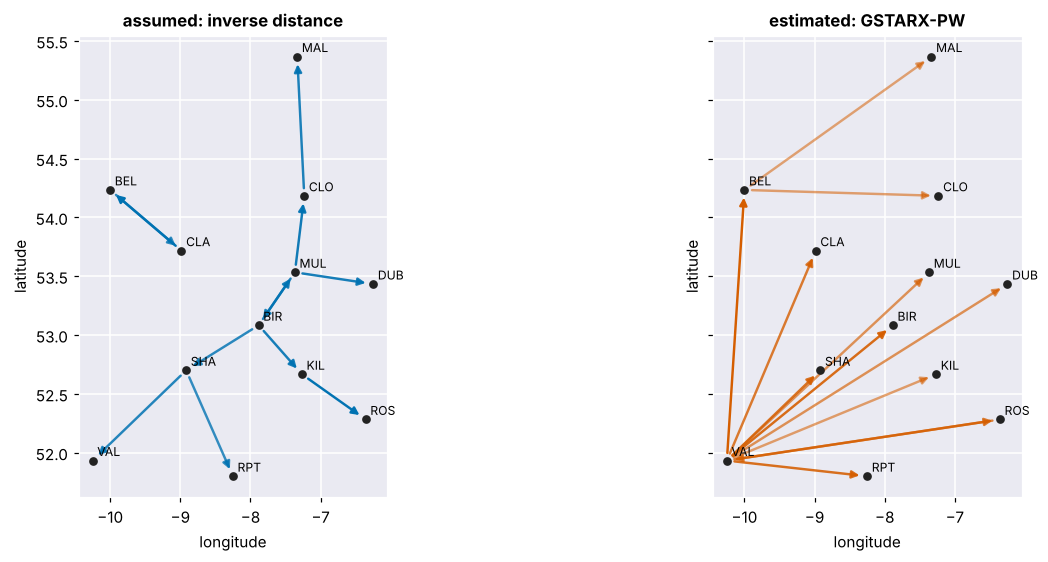

,strongest neighbour,weight,from the west
Roche's Point,Valentia,0.84,True
Valentia,Roslare,0.67,False
Roslare,Valentia,0.73,True
Kilkenny,Valentia,0.42,True
Shannon,Valentia,0.80,True
Birr,Valentia,0.87,True
Dublin,Valentia,0.53,True
Claremorris,Valentia,0.74,True
Mullingar,Valentia,0.53,True
Clones,Belmullet,0.40,True


In [5]:
W0 = cands['inverse distance']
kappa, fit = g.select_kappa(Zhat, W0)
west = [w['lon'][int(np.argmax(fit['W'][i]))] < w['lon'][i] for i in range(12)]
print('selected kappa:', kappa, '| strongest links coming from the west:', sum(west), 'of 12')
fig, ax = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True, constrained_layout=True)
plot_links(ax[0], w['lat'], w['lon'], W0, k=1, color=C[0], arrows=True, labels=w['codes']); ax[0].set_title('assumed: inverse distance')
plot_links(ax[1], w['lat'], w['lon'], fit['W'], k=1, color=C[1], arrows=True, labels=w['codes']); ax[1].set_title('estimated: GSTARX-PW')
for a in ax: a.set_aspect(1 / np.cos(np.radians(53.4)))
plt.show()
pd.DataFrame({'strongest neighbour': [w['stations'][int(np.argmax(fit['W'][i]))] for i in range(12)],
              'weight': [fit['W'][i].max().round(2) for i in range(12)], 'from the west': west}, index=w['stations'])

Weather systems reach Ireland from the Atlantic, so yesterday's wind at the western coastal stations (Valentia, Belmullet) carries information about today's wind further east. The inverse-distance matrix cannot represent this asymmetry; the estimated matrix shows it directly.

## 4. Forecasts

In [6]:
errs, _ = g.rolling_origin(Y, X, W0, window=730, H=3, step=7, kappa=kappa)
rmse = pd.DataFrame({m: np.sqrt((e ** 2).mean(axis=(0, 2))) for m, e in errs.items()}, index=['h=1', 'h=2', 'h=3'])
rmse.div(rmse['exog'], axis=0).round(3)

,exog,var,fixed,pw
h=1,1.0,0.758,0.802,0.786
h=2,1.0,0.941,0.965,0.945
h=3,1.0,0.974,0.988,0.969
